# Bonus Round: Rebuilding EDEN
Predict whether a planet is viable (`settlement_index >= 60`).

**Design.** Three candidates are compared on the same held-out 20% of the training planets (never used for fitting or tuning):
a logistic-regression baseline, a gradient-boosting *classifier*, and a gradient-boosting *regressor* that predicts the
settlement_index itself and then applies the >= 60 threshold (this keeps the full 0-100 information instead of only the yes/no label).
The winner (by F1, since the task gives no metric) is refitted on all training planets and used for the test set.
Preprocessing (one-hot encoding, scaling) is inside each pipeline, so nothing is learned from the validation or test planets.

In [1]:
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import loguniform, randint
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, r2_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

TEAM, THRESHOLD, SEED = "llcd", 60, 0
PARSE_GASES = True      # one numeric column per gas instead of a one-hot column per distinct atmosphere string (see feature check)
train = pd.read_csv(f"{TEAM}_cleaned_dataset.csv")          # output of the cleaning notebook
test = pd.read_csv(f"{TEAM}_cleaned_test.csv")              # the test set cleaned with the same (train-fitted) rules
sample = pd.read_csv("dataset/Bonus_Task/sample_submission.csv")

DROP = ["planetId", "planet_name", "settlement_index"]      # identifiers, and the target itself
PAT = re.compile(r"([A-Za-z0-9]+) (\d+(?:\.\d+)?)%")             # "N2 78% O2 18% Ar 3%" -> N2 78, O2 18, Ar 3
GASES = sorted({g for v in train.atmosphere_primary_gases for g, _ in PAT.findall(v)})


def features(df, parse=True):
    d = df.drop(columns=[c for c in DROP if c in df])
    if parse:
        gas = pd.DataFrame([{g: float(p) for g, p in PAT.findall(v)} for v in d.pop("atmosphere_primary_gases")], index=d.index)
        d = d.join(gas.reindex(columns=GASES).fillna(0).add_prefix("gas_"))
    return d


X, X_test = features(train, PARSE_GASES), features(test, PARSE_GASES)
assert list(X.columns) == list(X_test.columns)
y_cont = train.settlement_index
y_bin = y_cont >= THRESHOLD
n_cat = len(X.select_dtypes(exclude="number").columns)
print(f"{len(X)} training planets, {len(X.columns)} features ({n_cat} categorical, {len(X.columns) - n_cat} numeric); {len(GASES)} gases parsed")
print(f"viable: {y_bin.mean():.1%} -> always predicting the majority class scores {max(y_bin.mean(), 1 - y_bin.mean()):.1%} accuracy")

tr, va = train_test_split(train.index, test_size=0.2, stratify=y_bin, random_state=SEED)
Xtr, Xva, ytr_c, yva_c = X.loc[tr], X.loc[va], y_cont.loc[tr], y_cont.loc[va]
ytr_b, yva_b = ytr_c >= THRESHOLD, yva_c >= THRESHOLD

6400 training planets, 49 features (11 categorical, 38 numeric); 19 gases parsed
viable: 42.3% -> always predicting the majority class scores 57.7% accuracy


## Candidates

In [2]:
def pipe(est, data=None, scale=False):
    data = X if data is None else data
    cat, num = data.select_dtypes(exclude="number").columns.tolist(), data.select_dtypes("number").columns.tolist()
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
                             ("num", StandardScaler() if scale else "passthrough", num)])
    return Pipeline([("pre", pre), ("m", est)])


SPACE = {"m__learning_rate": loguniform(0.02, 0.2), "m__max_leaf_nodes": randint(8, 48), "m__min_samples_leaf": randint(10, 80),
         "m__l2_regularization": loguniform(1e-3, 10), "m__max_iter": randint(150, 500)}


def tuned(est, scoring):       # random search with 3-fold CV, on the training part only
    return RandomizedSearchCV(pipe(est), SPACE, n_iter=12, cv=3, scoring=scoring, random_state=SEED, n_jobs=-1)


models = {"Logistic regression": ("clf", pipe(LogisticRegression(max_iter=2000), scale=True)),
          "Boosting classifier": ("clf", tuned(HistGradientBoostingClassifier(random_state=SEED), "f1")),
          "Boosting regressor + threshold": ("reg", tuned(HistGradientBoostingRegressor(random_state=SEED), "neg_root_mean_squared_error"))}
CUT = {"clf": 0.5, "reg": THRESHOLD}      # decision cut-off: probability 0.5, or settlement_index 60


def decision(model, kind, data):
    """Continuous score whose cut-off CUT[kind] separates viable from not viable."""
    return model.predict(data) if kind == "reg" else model.predict_proba(data)[:, 1]

## Feature check: atmosphere string
`atmosphere_primary_gases` has hundreds of distinct values, so one-hot encoding it creates hundreds of mostly-empty columns and a
test planet with an unseen combination would get all zeros. Parsing it into one numeric column per gas avoids that. Quick check
(untuned boosting regressor, same validation planets):

In [3]:
abl = {}
for parse in (False, True):
    Xa = features(train, parse)
    abl[parse] = r2_score(yva_c, pipe(HistGradientBoostingRegressor(random_state=SEED), Xa).fit(Xa.loc[tr], ytr_c).predict(Xa.loc[va]))
print(f"validation R^2 of the settlement_index: raw one-hot atmosphere string {abl[False]:.3f} -> parsed gas columns {abl[True]:.3f}")
if (abl[True] < abl[False]) == PARSE_GASES:
    print("note: the setting PARSE_GASES at the top of the notebook is the weaker option here; flip it and re-run")

validation R^2 of the settlement_index: raw one-hot atmosphere string 0.832 -> parsed gas columns 0.832


## Compare on the held-out validation planets

In [4]:
rows, scores = [], {}
for name, (kind, m) in models.items():
    m.fit(Xtr, ytr_c if kind == "reg" else ytr_b)
    s = decision(m, kind, Xva)
    pred = s >= CUT[kind]
    scores[name] = s
    rows.append({"model": name, "accuracy": accuracy_score(yva_b, pred), "precision": precision_score(yva_b, pred),
                 "recall": recall_score(yva_b, pred), "F1": f1_score(yva_b, pred), "ROC_AUC": roc_auc_score(yva_b, s)})
res = pd.DataFrame(rows).set_index("model")
print(res.round(3).to_string())
best = res.F1.idxmax()
kind, model = models[best]
reg_r2 = r2_score(yva_c, scores["Boosting regressor + threshold"])
print(f"\nbest by F1: {best} | settlement_index R^2 of the boosting regressor on validation: {reg_r2:.3f}")

                                accuracy  precision  recall     F1  ROC_AUC
model                                                                      
Logistic regression                0.827      0.822   0.756  0.788    0.890
Boosting classifier                0.870      0.859   0.830  0.844    0.940
Boosting regressor + threshold     0.882      0.872   0.845  0.858    0.944

best by F1: Boosting regressor + threshold | settlement_index R^2 of the boosting regressor on validation: 0.840


## Where does the best model go wrong, and what does it rely on?

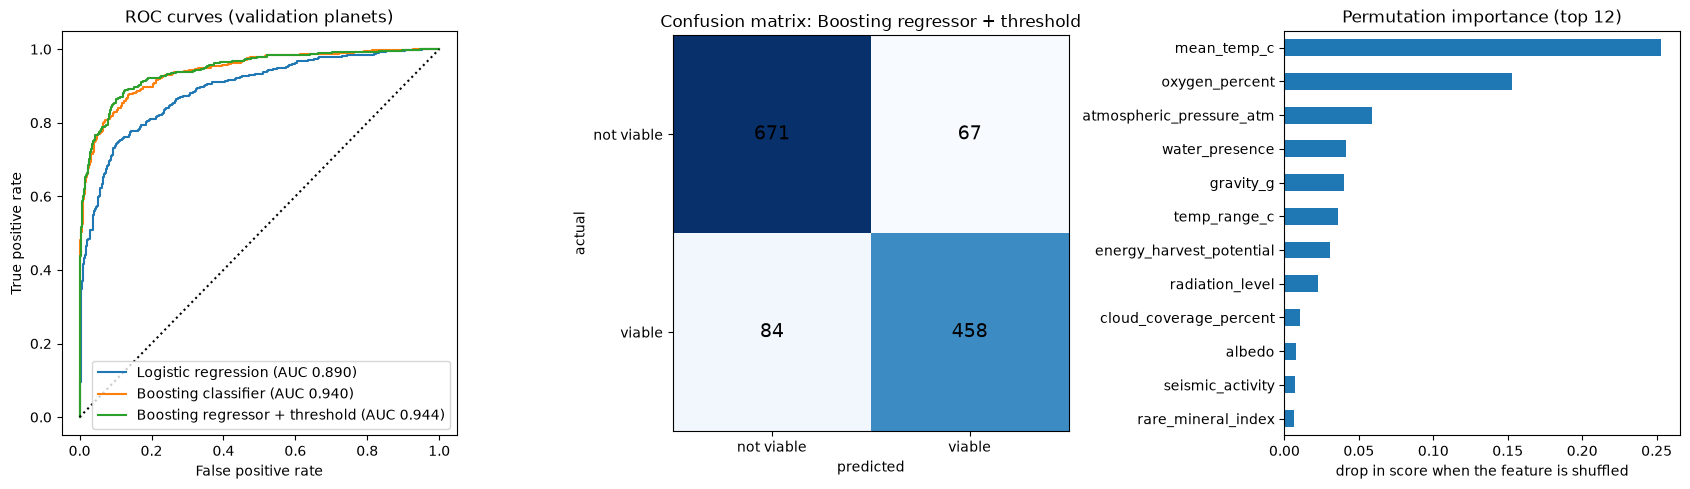

errors within 5 index points of the threshold: 118 of 151 (35% of planets lie that close); accuracy there 73.4% vs 96.1% elsewhere
mean_temp_c                 0.2530
oxygen_percent              0.1530
atmospheric_pressure_atm    0.0588
water_presence              0.0416
gravity_g                   0.0398
temp_range_c                0.0361
energy_harvest_potential    0.0305
radiation_level             0.0228
cloud_coverage_percent      0.0105
albedo                      0.0081


In [5]:
pred_va = scores[best] >= CUT[kind]
cm = confusion_matrix(yva_b, pred_va)
err, near = pred_va != yva_b, (yva_c - THRESHOLD).abs() < 5
imp = permutation_importance(model, Xva, yva_c if kind == "reg" else yva_b, scoring="r2" if kind == "reg" else "f1",
                             n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=X.columns).sort_values(ascending=False)

fig, (a, b, c) = plt.subplots(1, 3, figsize=(17, 5))
for name, s in scores.items():
    fpr, tpr, _ = roc_curve(yva_b, s)
    a.plot(fpr, tpr, label=f"{name} (AUC {res.loc[name, 'ROC_AUC']:.3f})")
a.plot([0, 1], [0, 1], "k:")
a.set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (validation planets)")
a.legend(loc="lower right")
b.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    b.text(j, i, v, ha="center", va="center", fontsize=14)
b.set(xticks=[0, 1], yticks=[0, 1], xticklabels=["not viable", "viable"], yticklabels=["not viable", "viable"],
      xlabel="predicted", ylabel="actual", title=f"Confusion matrix: {best}")
imp.head(12)[::-1].plot.barh(ax=c)
c.set(xlabel="drop in score when the feature is shuffled", title="Permutation importance (top 12)")
fig.tight_layout()
fig.savefig(f"{TEAM}_ml_results.png", dpi=120)
plt.show()
print(f"errors within 5 index points of the threshold: {err[near].sum()} of {err.sum()} "
      f"({near.mean():.0%} of planets lie that close); accuracy there {1 - err[near].mean():.1%} vs {1 - err[~near].mean():.1%} elsewhere")
print(imp.head(10).round(4).to_string())

## Refit the winner on all training planets and predict the test planets

In [6]:
final = clone(model.best_estimator_ if hasattr(model, "best_estimator_") else model)
final.fit(X, y_cont if kind == "reg" else y_bin)
viable = decision(final, kind, X_test) >= CUT[kind]
sub = sample[["planetId"]].merge(pd.DataFrame({"planetId": test.planetId, "viable_planet": viable}), on="planetId", how="left")
assert len(sub) == len(sample) and sub.viable_planet.notna().all()
sub["viable_planet"] = sub.viable_planet.astype(bool)
sub.to_csv(f"{TEAM}_predicted.csv", index=False)
print(f"wrote {TEAM}_predicted.csv: {len(sub)} planets, {sub.viable_planet.mean():.1%} predicted viable (training share: {y_bin.mean():.1%})")
print(sub.head(3).to_string(index=False))

wrote llcd_predicted.csv: 1600 planets, 41.2% predicted viable (training share: 42.3%)
 planetId  viable_planet
        9          False
       10          False
       11          False


## Written summary (`llcd_bonus_discussion.md`)

In [7]:
def md(d):
    return "\n".join(["| " + " | ".join(map(str, d.columns)) + " |", "|" + "---|" * len(d.columns)]
                     + ["| " + " | ".join(map(str, r)) + " |" for r in d.round(3).itertuples(index=False)])


lr, gain = res.loc["Logistic regression"], res.F1.max() - res.loc["Logistic regression", "F1"]
text = f"""# Bonus task: rebuilding EDEN (team {TEAM})

## Approach
A planet is viable when settlement_index >= {THRESHOLD}; {y_bin.mean():.1%} of the {len(X)} training planets are viable, so always guessing the majority class would score {max(y_bin.mean(), 1 - y_bin.mean()):.1%} accuracy. The model uses the {len(X.columns)} cleaned planet properties (identifiers and the target are excluded; categorical properties are one-hot encoded inside the pipeline{"; the atmosphere string is parsed into one numeric column per gas, which changed the untuned regressor's validation R^2 from " + f"{abl[False]:.3f} to {abl[True]:.3f}" if PARSE_GASES else ""}). Three candidates were compared on a stratified 20% hold-out ({len(Xva)} planets) that was never used for fitting or tuning: a logistic-regression baseline, a gradient-boosting classifier, and a gradient-boosting regressor that predicts the settlement_index and then applies the >= {THRESHOLD} threshold. The two boosting models were tuned by random search with 3-fold cross-validation on the training part only. The winner by F1 (the task names no metric) was refitted on all {len(X)} training planets to predict the {len(sub)} test planets.

## Results on the hold-out planets
{md(res.reset_index())}

The best model is **{best}**. {f"It beats the logistic-regression baseline by {gain:.3f} F1; this is consistent with the non-monotonic (Goldilocks) effects found in Part Two, where intermediate values of properties such as temperature are best: a linear model cannot represent them, whereas tree-based models can." if gain >= 0.02 else "It is about as good as the logistic-regression baseline, so the extra complexity buys little here."} The boosting regressor explains R^2 = {reg_r2:.2f} of the settlement_index on the hold-out planets. Confusion matrix of the best model (rows actual, columns predicted; not viable / viable): {cm.tolist()}.

![Results]({TEAM}_ml_results.png)

## Discussion
- **Where it errs.** {err[near].sum()} of the {err.sum()} misclassified hold-out planets ({err[near].sum() / max(err.sum(), 1):.0%}) have a true index within 5 points of the threshold, a band that contains {near.mean():.0%} of all planets. Accuracy is {1 - err[near].mean():.1%} inside that band and {1 - err[~near].mean():.1%} outside it, so most mistakes are planets that are genuinely borderline.
- **What it relies on.** The properties whose shuffling hurts the score most are: {", ".join(f"{k} ({v:.3f})" for k, v in imp.head(6).items())}.
- **Test predictions.** {sub.viable_planet.mean():.1%} of the {len(sub)} test planets are predicted viable, against {y_bin.mean():.1%} in the training data.

## Limitations
The validation set has {len(Xva)} planets, so the metrics carry a sampling error of roughly +/-{100 * 1.96 * np.sqrt(res.accuracy.max() * (1 - res.accuracy.max()) / len(Xva)):.1f} percentage points. The best of three candidates was picked on that same hold-out, so its score is slightly optimistic. Cleaning statistics (medians, label frequencies) were fitted on all training planets before splitting, a negligible leak. Importance is permutation-based and shares credit between correlated properties. The model learns associations in simulated data and says nothing about causes.
"""
Path(f"{TEAM}_bonus_discussion.md").write_text(text, encoding="utf-8")
print(f"wrote {TEAM}_bonus_discussion.md")

wrote llcd_bonus_discussion.md
